# 04 – Explainable AI: SHAP and LIME
**Deliverables covered:** #5 (proposed method), #6 (explanation experiments), #7 (visualizations), #8 (analysis).

Model explained: **E5 tuned Random Forest** (the black box). Reference: **E2 balanced Logistic Regression** (a glass box whose coefficients we can read directly).

Research questions
1. Which features does the model rely on most (global)?
2. Why did the model flag *this* customer (local)?
3. Do SHAP and LIME agree?
4. Are the explanations stable?
5. Can an explanation be read as a cause?

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from src.utils import *
sns.set_theme(style="whitegrid"); np.random.seed(SEED)

import joblib, shap
from lime.lime_tabular import LimeTabularExplainer
from scipy.stats import spearmanr
from sklearn.ensemble import RandomForestClassifier
X_train, X_test, y_train, y_test = load_split()
rf_pipe = joblib.load(MODELS_DIR/"E5_RF_tuned.joblib"); lr_pipe = joblib.load(MODELS_DIR/"E2_LR_balanced.joblib")
rf_pre, rf_clf = rf_pipe.named_steps["prep"], rf_pipe.named_steps["clf"]
Xtr = rf_pre.transform(X_train); Xte = rf_pre.transform(X_test)   # encoded, unscaled, DataFrames
feat = list(Xte.columns); print(len(feat), "encoded features")
p_te = rf_clf.predict_proba(Xte)[:,1]

40 encoded features


## 1. SHAP – global explanation

In [2]:
# Explain a stratified-random sample of the test set (TreeExplainer is exact but slower on deep forests)
rng = np.random.RandomState(SEED)
idx = np.sort(rng.choice(len(Xte), size=min(600,len(Xte)), replace=False))
Xs = Xte.iloc[idx]
explainer = shap.TreeExplainer(rf_clf)
sv, base = shap_positive_class(explainer, Xs)
print("shap values:", sv.shape, "| base value (mean predicted churn prob):", round(base,3))
# Local accuracy check: base + sum(shap) must equal the model output
print("max |base+sum(SHAP) - predict_proba|:", np.abs(base+sv.sum(1) - rf_clf.predict_proba(Xs)[:,1]).max())

shap values: (600, 40) | base value (mean predicted churn prob): 0.265
max |base+sum(SHAP) - predict_proba|: 1.5543122344752192e-15


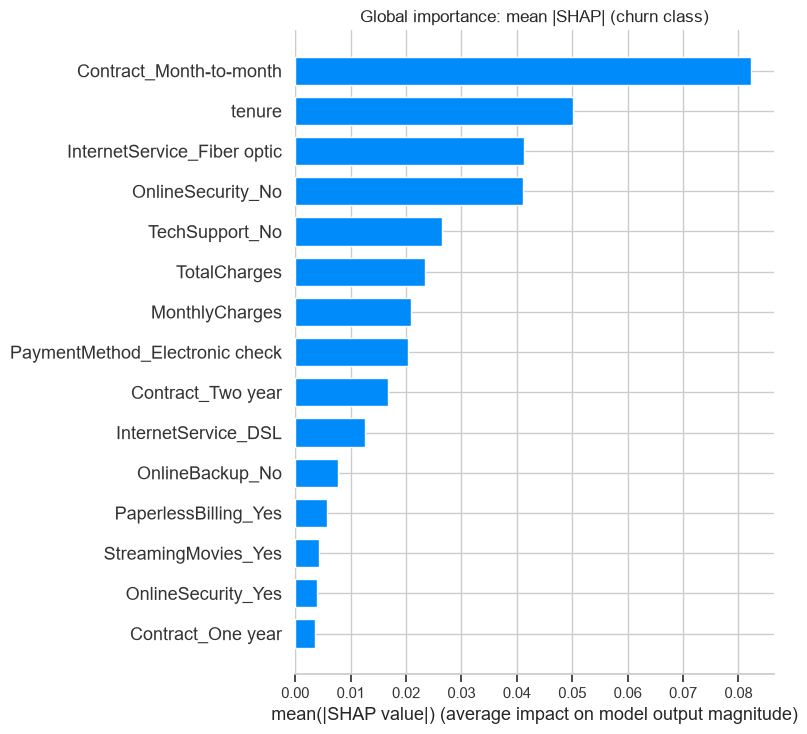

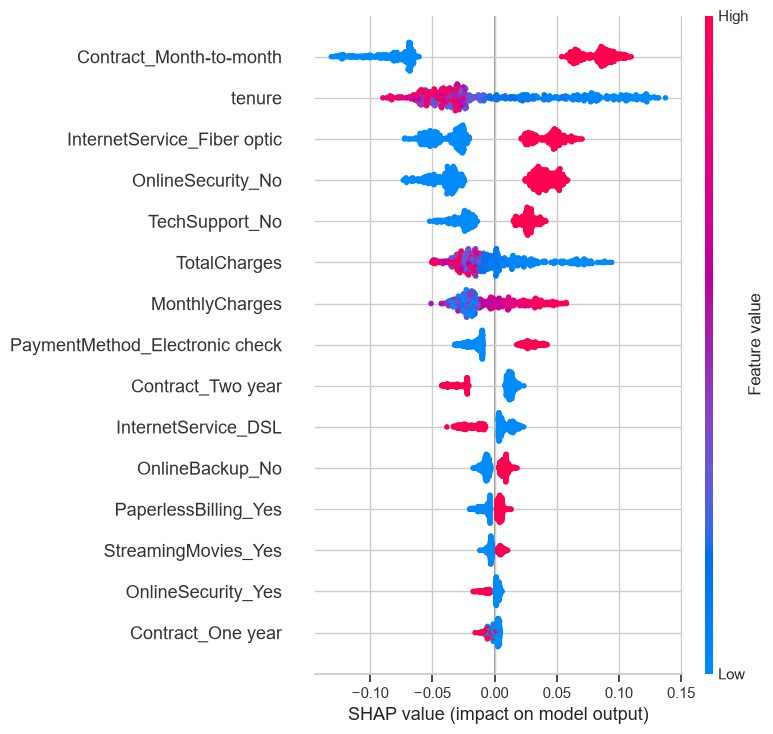

In [3]:
plt.figure(); shap.summary_plot(sv, Xs, plot_type="bar", max_display=15, show=False)
plt.title("Global importance: mean |SHAP| (churn class)"); plt.tight_layout()
plt.savefig(VIS_DIR/"global_shap_bar.png", dpi=150, bbox_inches="tight"); plt.show()
plt.figure(); shap.summary_plot(sv, Xs, max_display=15, show=False); plt.tight_layout()
plt.savefig(VIS_DIR/"global_shap.png", dpi=150, bbox_inches="tight"); plt.show()

In [4]:
imp = pd.Series(np.abs(sv).mean(0), index=feat).sort_values(ascending=False)
imp.to_csv(RESULTS_DIR/"shap_global_importance.csv"); imp.head(10).round(4)

Contract_Month-to-month           0.0823
tenure                            0.0502
InternetService_Fiber optic       0.0414
OnlineSecurity_No                 0.0412
TechSupport_No                    0.0265
TotalCharges                      0.0234
MonthlyCharges                    0.0210
PaymentMethod_Electronic check    0.0203
Contract_Two year                 0.0167
InternetService_DSL               0.0126
dtype: float64

**How to read the beeswarm:** each dot is a customer; x-position = push toward (right) or away from (left) churn; colour = feature value (red high, blue low). Write down, for the top 5 features, *which direction* each value pushes the prediction (e.g. low `tenure` -> pushes toward churn).

### Dependence plots (feature effect and interaction)

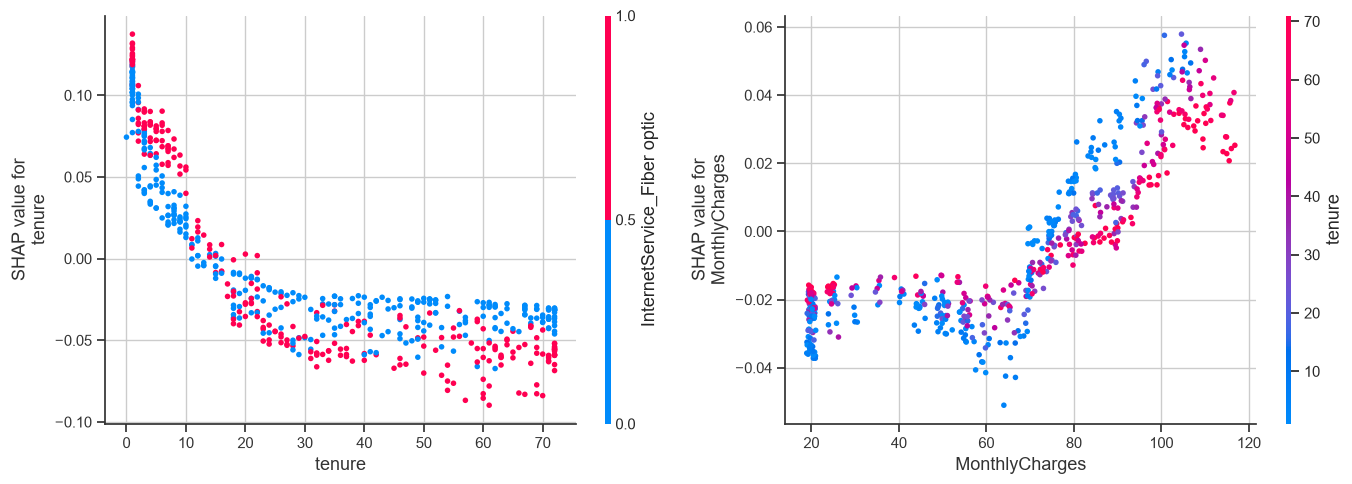

In [5]:
fig, axes = plt.subplots(1,2, figsize=(14,5))
shap.dependence_plot("tenure", sv, Xs, interaction_index="auto", ax=axes[0], show=False)
shap.dependence_plot("MonthlyCharges", sv, Xs, interaction_index="auto", ax=axes[1], show=False)
plt.tight_layout(); plt.savefig(VIS_DIR/"shap_dependence.png", dpi=150, bbox_inches="tight"); plt.show()

## 2. SHAP – local explanations (three customers)

In [6]:
# Choose 3 contrasting cases from the sample: confident churner (TP), confident loyal customer (TN), missed churner (FN)
ys = y_test.iloc[idx].values; ps = p_te[idx]
cands = {
  "1_confident_churner": np.where((ys==1))[0][np.argmax(ps[ys==1])],
  "2_confident_loyal":   np.where((ys==0))[0][np.argmin(ps[ys==0])],
  "3_missed_churner":    np.where((ys==1))[0][np.argmin(ps[ys==1])],
}
for k,i in cands.items():
    print(k, "| true churn:", ys[i], "| P(churn)=%.2f"%ps[i]); display(X_test.iloc[idx[i]].to_frame().T)

1_confident_churner | true churn: 1 | P(churn)=0.84


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
3380,Male,Yes,Yes,No,1,Yes,Yes,Fiber optic,No,No,No,No,Yes,Yes,Month-to-month,Yes,Electronic check,95.1,95.1


2_confident_loyal | true churn: 0 | P(churn)=0.01


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
165,Male,No,Yes,No,69,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.9,1363.45


3_missed_churner | true churn: 1 | P(churn)=0.05


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
2894,Female,No,No,No,48,Yes,No,DSL,Yes,No,Yes,Yes,No,No,One year,Yes,Credit card (automatic),60.35,2896.4


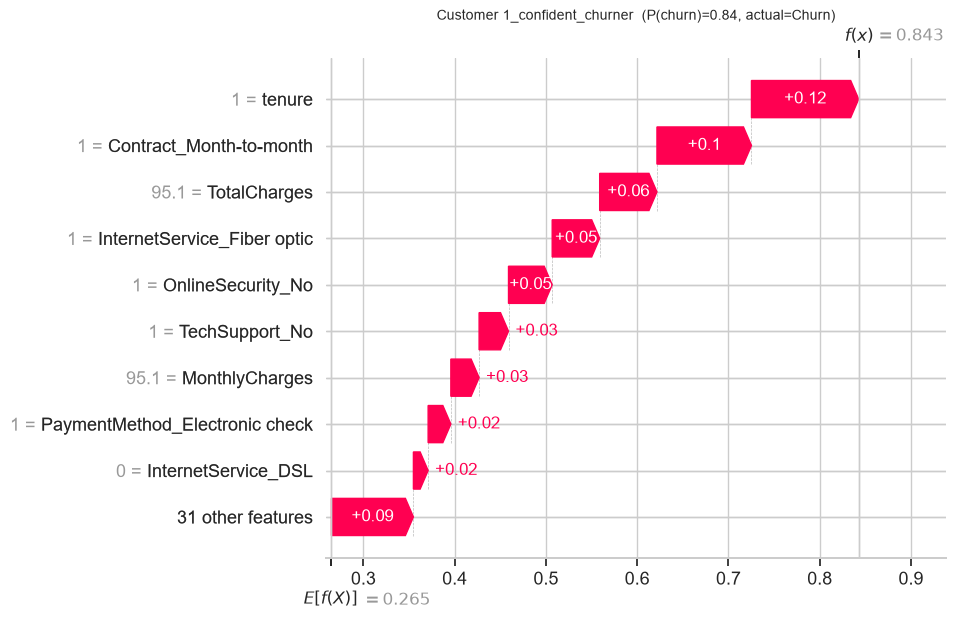

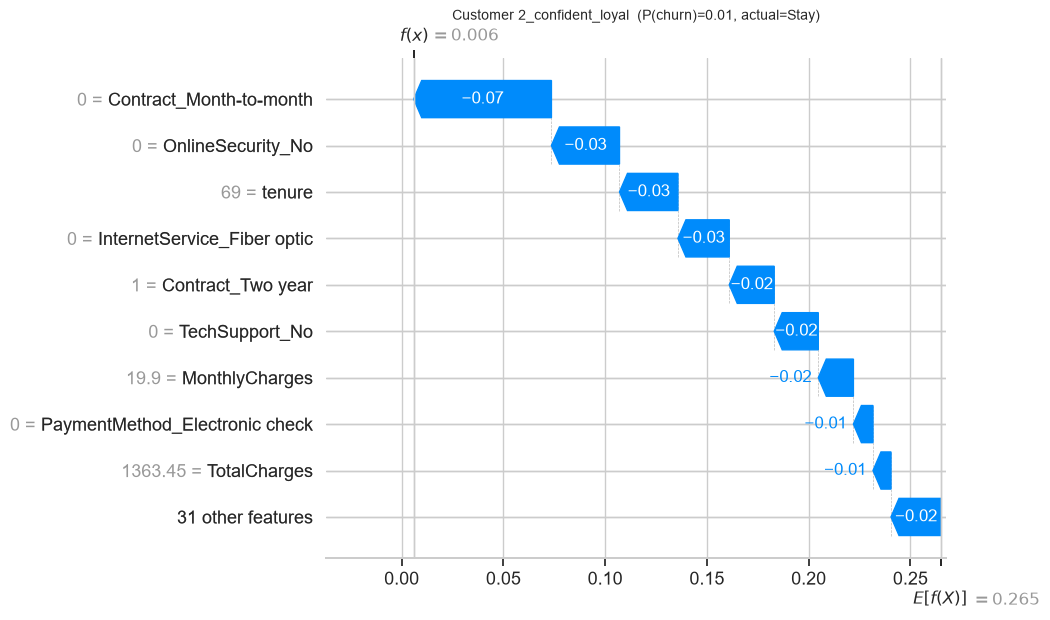

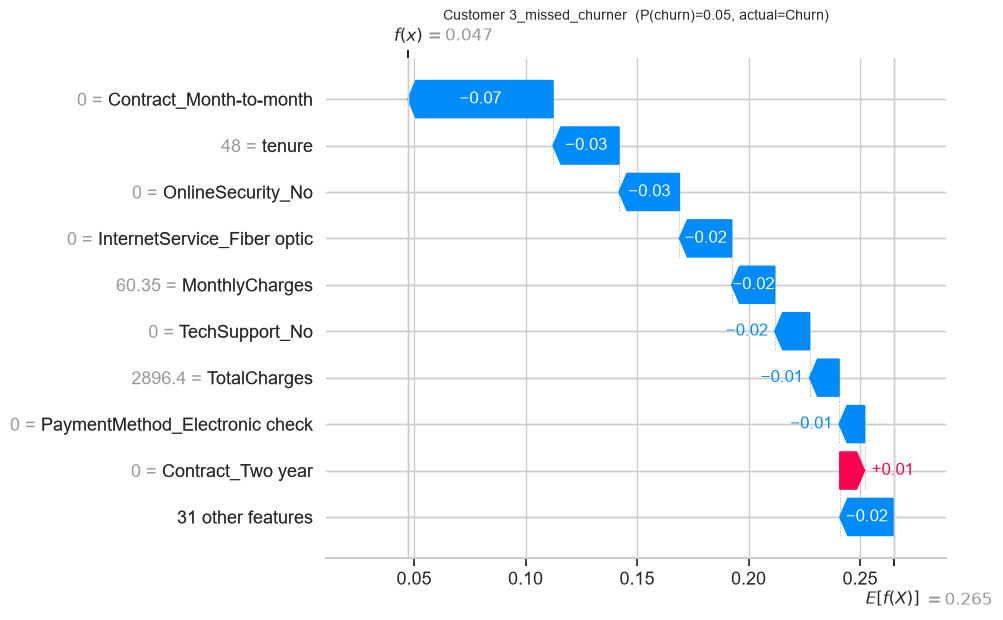

In [7]:
for k,i in cands.items():
    e = shap.Explanation(values=sv[i], base_values=base, data=Xs.iloc[i].values, feature_names=feat)
    plt.figure(); shap.plots.waterfall(e, max_display=10, show=False)
    plt.title(f"Customer {k}  (P(churn)={ps[i]:.2f}, actual={'Churn' if ys[i] else 'Stay'})", fontsize=10)
    plt.savefig(VIS_DIR/f"local_shap_{k[0]}.png", dpi=150, bbox_inches="tight"); plt.show()

**Write-up prompt:** for each customer list the top 3 pushes up and down. For customer 3 (a churner the model missed), explain *why the model was fooled* – which features looked "loyal"? What does that say about the limits of the data?

## 3. LIME – same three customers

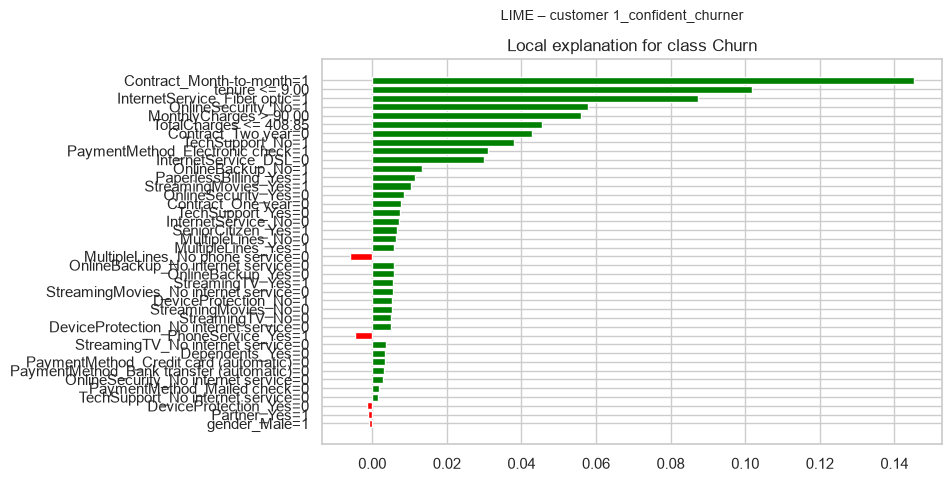

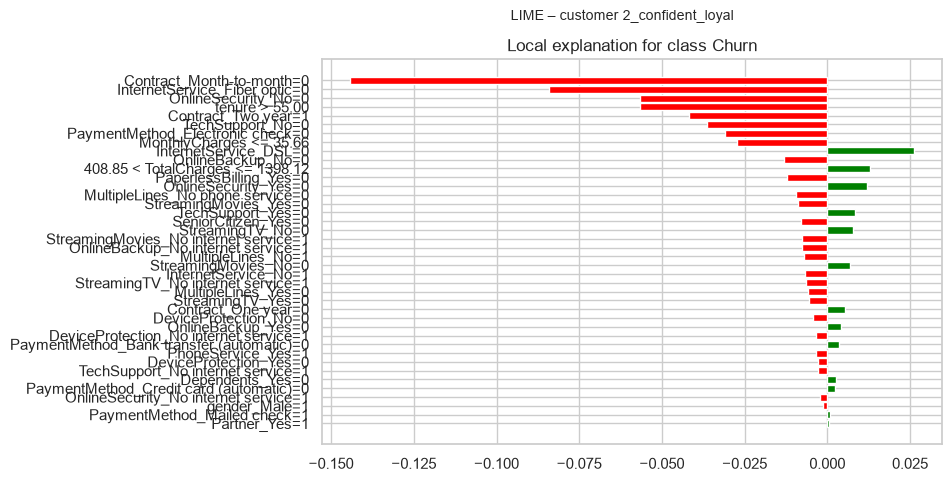

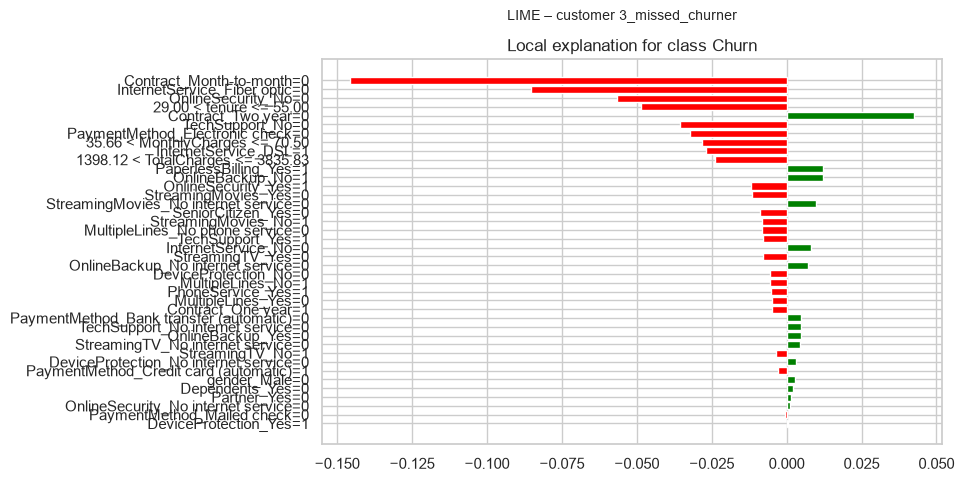

In [8]:
class_names = ["Stay","Churn"]
binary_cols = [i for i,c in enumerate(feat) if set(Xtr[c].unique()) <= {0,1}]     # one-hot / binary columns
lime_exp = LimeTabularExplainer(Xtr.values, feature_names=feat, class_names=class_names,
                                categorical_features=binary_cols, discretize_continuous=True, random_state=SEED)
predict_fn = lambda a: rf_clf.predict_proba(pd.DataFrame(a, columns=feat))
def lime_weights(i, seed=SEED, n=5000):
    lime_exp.random_state = np.random.RandomState(seed)
    e = lime_exp.explain_instance(Xs.iloc[i].values, predict_fn, num_features=len(feat), num_samples=n, labels=(1,))
    w = pd.Series(0.0, index=feat)
    for j,v in e.as_map()[1]: w.iloc[j]=v
    return w, e
lime_w = {}
for k,i in cands.items():
    lime_w[k], e = lime_weights(i)
    fig = e.as_pyplot_figure(label=1); fig.set_size_inches(8,5); fig.suptitle(f"LIME – customer {k}", fontsize=10)
    fig.savefig(VIS_DIR/f"local_lime_{k[0]}.png", dpi=150, bbox_inches="tight"); plt.show()

## 4. SHAP vs LIME comparison

In [9]:
def topk(s, k=5): return set(s.abs().sort_values(ascending=False).index[:k])
rows=[]
for k,i in cands.items():
    s = pd.Series(sv[i], index=feat); l = lime_w[k]
    rows.append({"customer":k, "spearman_all_features":spearmanr(s,l)[0], "top5_overlap":len(topk(s)&topk(l)),
                 "sign_agreement_top5": np.mean([np.sign(s[f])==np.sign(l[f]) for f in topk(s)])})
cmp3 = pd.DataFrame(rows).set_index("customer"); cmp3.round(3).to_csv(RESULTS_DIR/"shap_vs_lime_3customers.csv"); cmp3.round(3)

,spearman_all_features,top5_overlap,sign_agreement_top5
customer,,,
1_confident_churner,0.950,4,1.0
2_confident_loyal,0.835,5,1.0
3_missed_churner,0.935,4,1.0


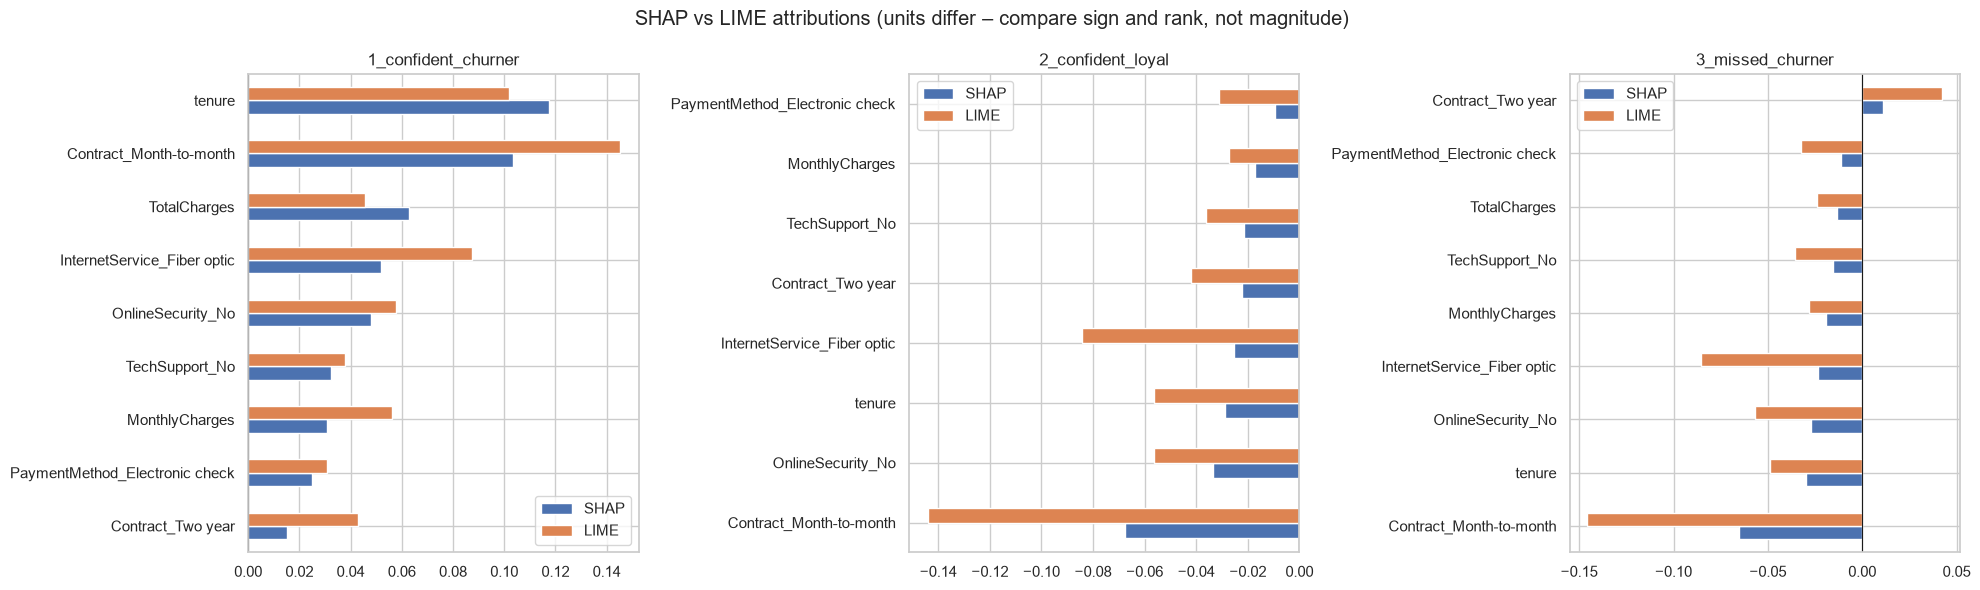

In [10]:
fig, axes = plt.subplots(1,3, figsize=(20,6))
for ax,(k,i) in zip(axes, cands.items()):
    s = pd.Series(sv[i], index=feat); l = lime_w[k]
    top = list(topk(s,8)|topk(l,8))
    d = pd.DataFrame({"SHAP":s[top],"LIME":l[top]}).sort_values("SHAP")
    d.plot(kind="barh", ax=ax); ax.set_title(k); ax.axvline(0,c="k",lw=.8)
plt.suptitle("SHAP vs LIME attributions (units differ – compare sign and rank, not magnitude)"); plt.tight_layout()
plt.savefig(VIS_DIR/"shap_vs_lime.png", dpi=150, bbox_inches="tight"); plt.show()

### Agreement over many customers (50 random customers)

      spearman  top5_overlap
mean     0.871         4.060
std      0.047         0.712
min      0.736         3.000
max      0.947         5.000


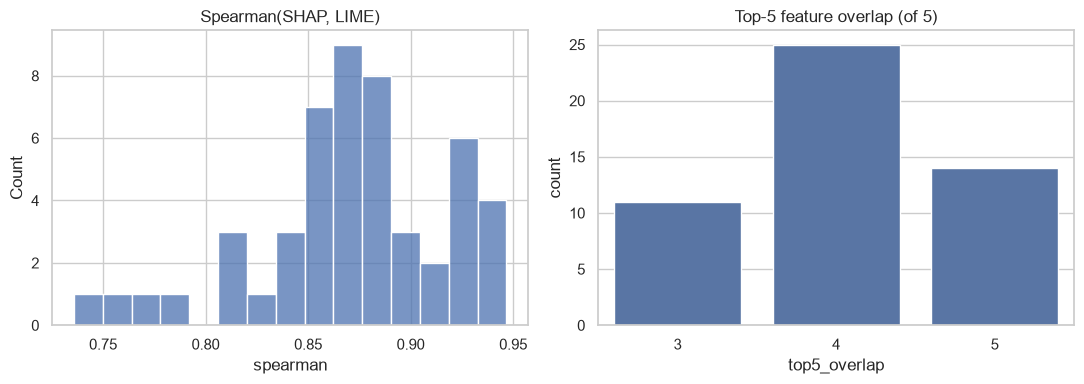

In [11]:
sub = rng.choice(len(Xs), 50, replace=False); R=[]
for i in sub:
    s = pd.Series(sv[i], index=feat); l,_ = lime_weights(i, n=2000)
    R.append({"spearman":spearmanr(s,l)[0], "top5_overlap":len(topk(s)&topk(l))})
R = pd.DataFrame(R); R.to_csv(RESULTS_DIR/"shap_vs_lime_50customers.csv", index=False)
print(R.describe().loc[["mean","std","min","max"]].round(3))
fig,ax = plt.subplots(1,2, figsize=(11,4)); sns.histplot(R.spearman, bins=15, ax=ax[0]); ax[0].set_title("Spearman(SHAP, LIME)")
sns.countplot(x=R.top5_overlap, ax=ax[1]); ax[1].set_title("Top-5 feature overlap (of 5)")
plt.tight_layout(); plt.savefig(VIS_DIR/"shap_lime_agreement.png", dpi=150); plt.show()

## 5. Stability of explanations

**5a. LIME run-to-run stability** – same customer, same model, different random seeds.

In [12]:
i = cands["1_confident_churner"]
W = pd.DataFrame({s: lime_weights(i, seed=s)[0] for s in range(5)})
pairs = [spearmanr(W[a],W[b])[0] for a in W for b in W if a<b]
tops = [topk(W[s]) for s in W]; common = set.intersection(*tops)
print("Mean pairwise Spearman across 5 LIME seeds: %.3f"%np.mean(pairs)); print("Features in top-5 for ALL seeds:", common)
W.loc[sorted(set().union(*tops))].round(3)

Mean pairwise Spearman across 5 LIME seeds: 0.930
Features in top-5 for ALL seeds: {'InternetService_Fiber optic', 'OnlineSecurity_No', 'Contract_Month-to-month', 'tenure', 'MonthlyCharges'}


,0,1,2,3,4
Contract_Month-to-month,0.147,0.145,0.146,0.147,0.145
InternetService_Fiber optic,0.086,0.085,0.085,0.086,0.084
MonthlyCharges,0.055,0.056,0.056,0.057,0.055
OnlineSecurity_No,0.057,0.057,0.059,0.057,0.058
tenure,0.103,0.104,0.101,0.102,0.103


**5b. SHAP model-to-model stability** – retrain the same Random Forest with 4 different seeds (and one 80% bootstrap-style subsample) and compare global rankings.

In [13]:
params = {k:v for k,v in rf_clf.get_params().items() if k not in ("random_state","n_jobs")}
imps = {}
for sd in [1,2,3,4]:
    m = RandomForestClassifier(**params, random_state=sd, n_jobs=-1).fit(Xtr, y_train)
    s,_ = shap_positive_class(shap.TreeExplainer(m), Xs.iloc[:300]); imps[f"seed_{sd}"] = np.abs(s).mean(0)
sub_i = rng.choice(len(Xtr), int(.8*len(Xtr)), replace=False)
m = RandomForestClassifier(**params, random_state=SEED, n_jobs=-1).fit(Xtr.iloc[sub_i], y_train.iloc[sub_i])
s,_ = shap_positive_class(shap.TreeExplainer(m), Xs.iloc[:300]); imps["80pct_data"] = np.abs(s).mean(0)
imps["original"] = np.abs(sv[:300]).mean(0)
I = pd.DataFrame(imps, index=feat)
print("Spearman rank correlation of global importance between runs:"); display(I.corr(method="spearman").round(3))
print("Top-5 per run:"); display(pd.DataFrame({c: I[c].nlargest(5).index.tolist() for c in I}))

Spearman rank correlation of global importance between runs:


,seed_1,seed_2,seed_3,seed_4,80pct_data,original
seed_1,1.000,0.968,0.975,0.966,0.953,0.972
seed_2,0.968,1.000,0.962,0.974,0.954,0.972
seed_3,0.975,0.962,1.000,0.948,0.968,0.974
seed_4,0.966,0.974,0.948,1.000,0.936,0.948
80pct_data,0.953,0.954,0.968,0.936,1.000,0.976
original,0.972,0.972,0.974,0.948,0.976,1.000


Top-5 per run:


,seed_1,seed_2,seed_3,seed_4,80pct_data,original
0,Contract_Month-to-month,Contract_Month-to-month,Contract_Month-to-month,Contract_Month-to-month,Contract_Month-to-month,Contract_Month-to-month
1,tenure,tenure,tenure,tenure,tenure,tenure
2,InternetService_Fiber optic,InternetService_Fiber optic,InternetService_Fiber optic,InternetService_Fiber optic,OnlineSecurity_No,InternetService_Fiber optic
3,OnlineSecurity_No,OnlineSecurity_No,OnlineSecurity_No,OnlineSecurity_No,InternetService_Fiber optic,OnlineSecurity_No
4,TechSupport_No,TechSupport_No,TechSupport_No,TechSupport_No,TechSupport_No,TechSupport_No


**5c. Explanation consistency across customers** – do different customers get different explanations?

In [14]:
top1 = pd.Series(feat)[np.abs(sv).argmax(1)].value_counts()
print("Most influential feature per customer (n=%d):"%len(sv)); display(top1.head(8))

Most influential feature per customer (n=600):


Contract_Month-to-month        511
tenure                          73
OnlineSecurity_No                9
InternetService_Fiber optic      7
Name: count, dtype: int64

## 6. Glass-box vs black-box: Logistic Regression coefficients vs Random Forest SHAP

Spearman(|LR coef|, RF mean|SHAP|): 0.419


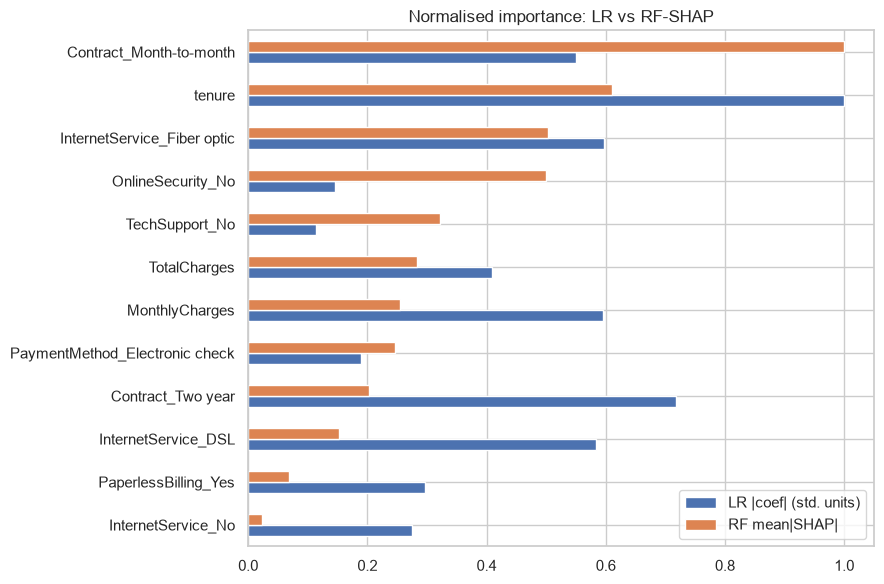

In [15]:
lr_pre, lr_clf = lr_pipe.named_steps["prep"], lr_pipe.named_steps["clf"]
coef = pd.Series(lr_clf.coef_[0], index=lr_pre.get_feature_names_out())
common = [f for f in feat if f in coef.index]
print("Spearman(|LR coef|, RF mean|SHAP|): %.3f"%spearmanr(coef[common].abs(), imp[common])[0])
d = pd.DataFrame({"LR |coef| (std. units)":coef[common].abs(), "RF mean|SHAP|":imp[common]})
d = d/d.max(); top = d.sum(1).nlargest(12).index
d.loc[top].sort_values("RF mean|SHAP|").plot(kind="barh", figsize=(9,6)); plt.title("Normalised importance: LR vs RF-SHAP")
plt.tight_layout(); plt.savefig(VIS_DIR/"lr_vs_rf_importance.png", dpi=150); plt.show()

## 7. Can an explanation be read as a cause? (central discussion)

SHAP and LIME describe **how the model uses features to predict**, not how the world works.

* **Confounding / reverse causality:** `Contract = Month-to-month` has a large SHAP effect, but dissatisfied or uncertain customers may *choose* monthly plans. Forcing a customer onto a 2-year contract would not necessarily stop them leaving.
* **Correlated features:** `tenure`, `TotalCharges` and `MonthlyCharges` are linked (EDA 4), and many service columns are collinear with `InternetService`. SHAP/LIME split credit among them, so a single feature's importance is partly arbitrary.
* **Observational data:** the dataset is a snapshot; there was no randomised intervention.
* **Model dependence:** a different model (see section 6) can give a different ranking; explanations explain *this model*, not "the truth".
* **Method dependence and instability:** LIME depends on sampling and kernel width (5a); SHAP depends on the background/tree-path distribution and the trained model (5b).
* **Fairness/sensitive features:** `gender` and `SeniorCitizen` should be checked in the SHAP plots; a feature appearing unimportant does not prove the model is fair (proxies exist).

**Safe wording for the report:** "The model associates month-to-month contracts with higher churn risk", **not** "month-to-month contracts cause churn". Use explanations to *generate hypotheses* (e.g. test a retention offer via an A/B experiment), not to claim effects.

## 8. Summary template (fill with your actual numbers)
* Top global features (SHAP): ...
* Direction of effects: ...
* SHAP vs LIME: mean Spearman = ..., mean top-5 overlap = ...
* LIME stability: ...  | SHAP across seeds: ...
* LR vs RF importance agreement: ...
* Limits: ...